# 03 · Topics: what do players complain about and praise?

Two complementary methods:

- **Part A, keyword themes** (fast, fully transparent): count how many reviews mention bugs, price, developers, and so on, then track that share over time. This answers "did the complaints change after the fixes?" directly.
- **Part B, BERTopic** (discovery): finds topics you did not think to look for, per game, in complaints and in praise.

**Input:** `data/processed/reviews_scored.csv` (from notebook 02)  
**Output:** theme and topic tables in `data/processed/`, charts in `images/`

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROC = Path("../data/processed")
IMG = Path("../images")
IMG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

df = pd.read_csv(PROC / "reviews_scored.csv", parse_dates=["month"])
df["text"] = df["review"].astype(str).str.lower()
df["half"] = df["month"].dt.year.astype(str) + "-H" + (((df["month"].dt.month - 1) // 6) + 1).astype(str)
complaints = df[df["recommended"] == 0]
praise = df[df["recommended"] == 1]
print(f"{len(df):,} reviews | {len(complaints):,} thumbs-down | {len(praise):,} thumbs-up")
df.groupby("game")["recommended"].agg(reviews="size", pct_positive=lambda s: round(100 * s.mean(), 1))

237,811 reviews | 34,947 thumbs-down | 202,864 thumbs-up


,reviews,pct_positive
game,,
Battlefield 2042,30235,50.7
Cyberpunk 2077,42386,89.4
Helldivers 2,19565,74.0
No Man's Sky,70128,86.8
Stardew Valley,75497,98.4


## Part A · Keyword themes

Each theme is a list of words. A review "mentions" a theme if it contains any of them. Edit the lists freely, for example by adding a game's character names or mechanics. A review can mention several themes, so shares do not add up to 100%.

In [2]:
THEMES = {
    "Bugs and crashes":        r"\b(?:bug|bugs|buggy|crash|crashes|crashing|glitch|glitches|glitchy|broken|freez\w*|unplayable)\b",
    "Performance":             r"\b(?:fps|stutter\w*|lag|laggy|performance|optimi[sz]\w*|framerate|frame rate|gpu|cpu)\b",
    "Price and value":         r"\b(?:price|priced|money|refund\w*|worth|overpriced|expensive|waste|bucks|full price)\b",
    "Developers and updates":  r"\b(?:dev|devs|developer|developers|update|updates|patch|patches|nerf\w*|hotfix|studio|publisher)\b",
    "Multiplayer and servers": r"\b(?:server\w*|matchmaking|multiplayer|co-?op|online|disconnect\w*|netcode|lobby|lobbies|login|account)\b",
    "Cheating and security":   r"\b(?:cheat\w*|hacker\w*|anti-?cheat|secure boot|kernel)\b",
    "Content and repetition":  r"\b(?:boring|repetitive|repetition|grind\w*|empty|shallow|lacks?|tedious|samey|same thing)\b",
    "Story and characters":    r"\b(?:story|plot|characters?|narrative|writing|quests?|ending)\b",
    "Controls and interface":  r"\b(?:controls?|ui|menus?|interface|inventory|controller|keyboard)\b",
}

def tag_themes(frame):
    out = pd.DataFrame(index=frame.index)
    for name, pattern in THEMES.items():
        out[name] = frame["text"].str.contains(pattern, regex=True)
    return out

tags_c = tag_themes(complaints)
tags_p = tag_themes(praise)
print("tagged", len(tags_c), "complaints and", len(tags_p), "praise reviews")

tagged 34947 complaints and 202864 praise reviews


### Which themes dominate the complaints in each game?

In [3]:
share_c = (tags_c.groupby(complaints["game"]).mean() * 100).round(1)
share_c

,Bugs and crashes,Performance,Price and value,Developers and updates,Multiplayer and servers,Cheating and security,Content and repetition,Story and characters,Controls and interface
game,,,,,,,,,
Battlefield 2042,16.9,8.8,22.9,11.1,11.1,9.7,6.4,3.1,4.2
Cyberpunk 2077,41.1,8.2,21.8,19.5,1.7,0.5,16.6,32.5,6.0
Helldivers 2,34.1,12.4,15.4,48.6,9.1,9.0,12.2,3.8,2.9
No Man's Sky,25.7,7.0,28.0,23.3,10.4,0.7,28.2,15.5,15.7
Stardew Valley,7.9,0.8,13.6,6.7,6.9,0.5,25.0,12.0,6.3


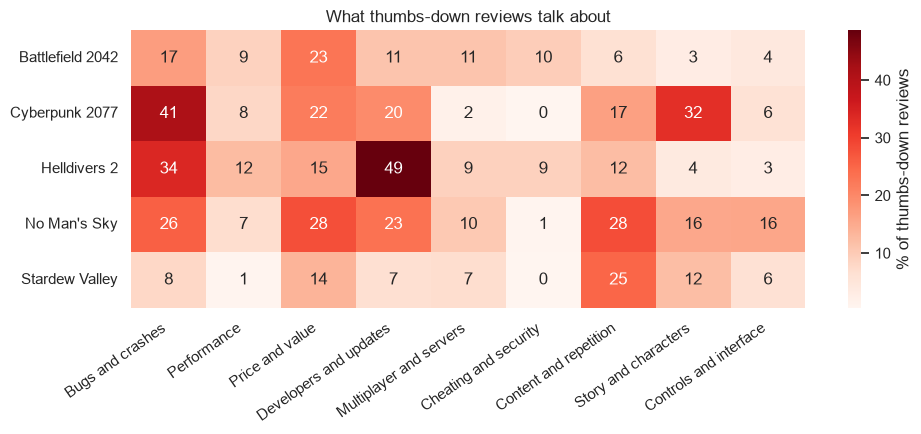

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(share_c, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% of thumbs-down reviews"}, ax=ax)
ax.set(title="What thumbs-down reviews talk about", xlabel="", ylabel="")
plt.xticks(rotation=35, ha="right")
fig.tight_layout()
fig.savefig(IMG / "complaint_themes_by_game.png", dpi=150)
plt.show()

### What do thumbs-up reviews talk about?

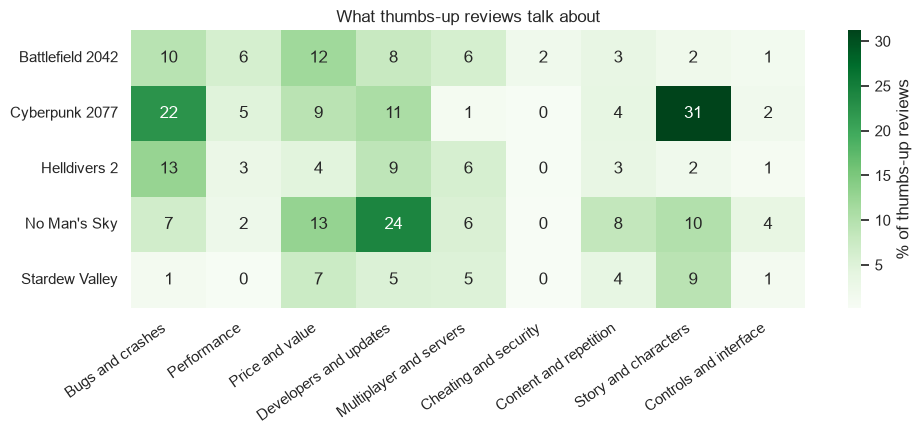

In [5]:
share_p = (tags_p.groupby(praise["game"]).mean() * 100).round(1)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(share_p, annot=True, fmt=".0f", cmap="Greens", cbar_kws={"label": "% of thumbs-up reviews"}, ax=ax)
ax.set(title="What thumbs-up reviews talk about", xlabel="", ylabel="")
plt.xticks(rotation=35, ha="right")
fig.tight_layout()
fig.savefig(IMG / "praise_themes_by_game.png", dpi=150)
plt.show()

### Did the complaints change over time?

For each game, the share of thumbs-down reviews mentioning each theme, by half-year. Half-years with fewer than 100 thumbs-down reviews are hidden because the percentages would be unreliable.

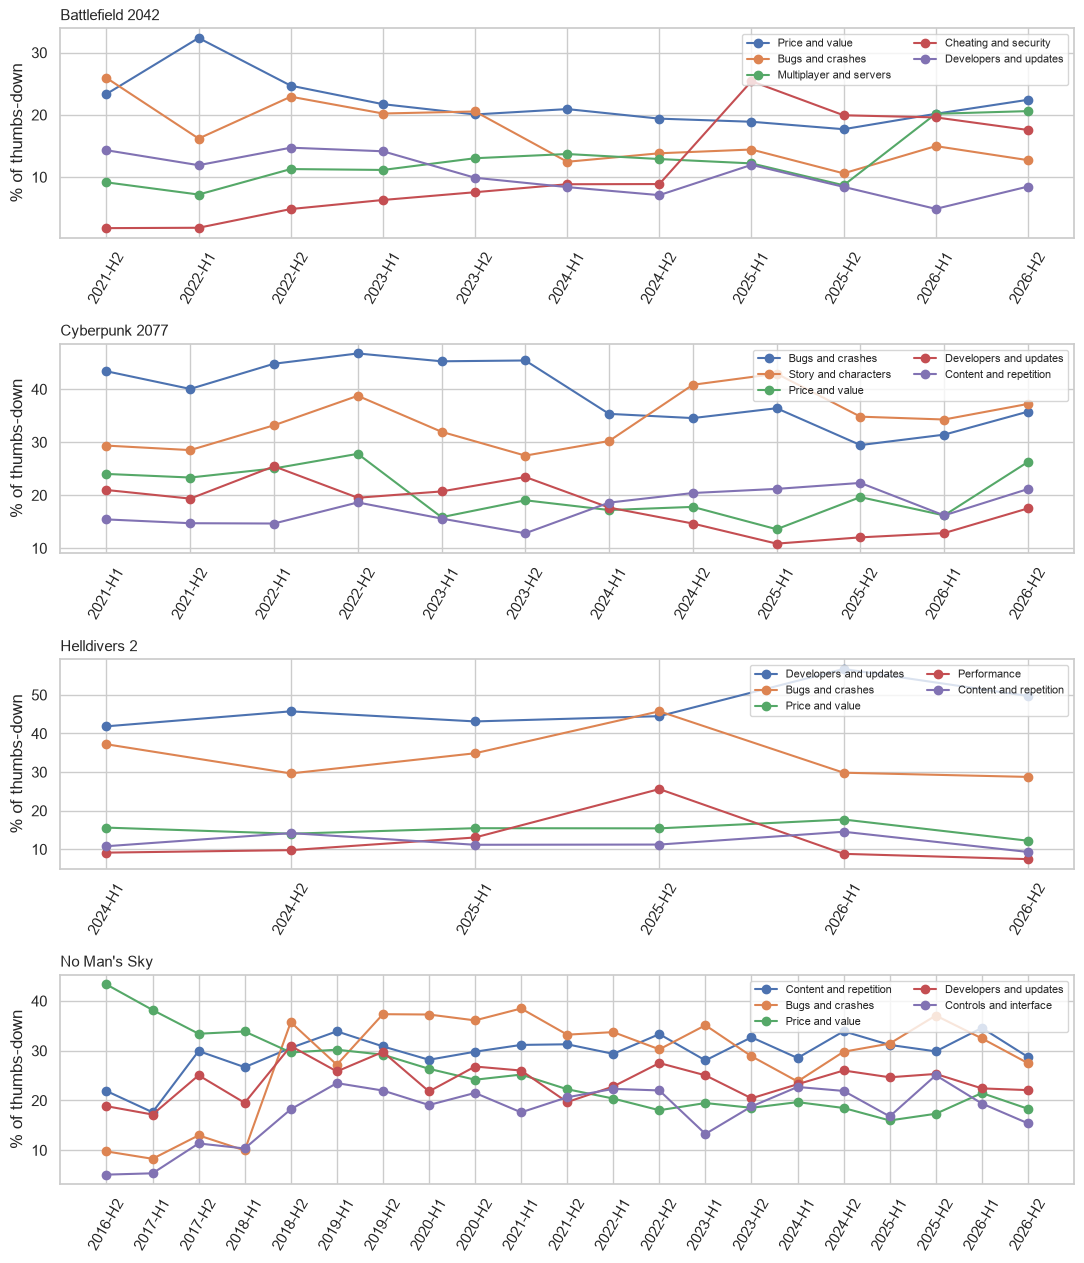

In [6]:
MIN_COMPLAINTS = 100
TOP_THEMES = 5

by_half = tags_c.groupby([complaints["game"], complaints["half"]]).mean() * 100
sizes = complaints.groupby(["game", "half"]).size().rename("n")
by_half = by_half.join(sizes)
by_half = by_half[by_half["n"] >= MIN_COMPLAINTS]

games = sorted(by_half.index.get_level_values("game").unique())
fig, axes = plt.subplots(len(games), 1, figsize=(11, 3.2 * len(games)), sharex=False)
axes = np.atleast_1d(axes)
for ax, game in zip(axes, games):
    g = by_half.loc[game].drop(columns="n")
    top = g.mean().sort_values(ascending=False).head(TOP_THEMES).index
    for theme in top:
        ax.plot(g.index, g[theme], marker="o", label=theme)
    ax.set_title(game, loc="left", fontsize=11)
    ax.set_ylabel("% of thumbs-down")
    ax.tick_params(axis="x", rotation=60)
    ax.legend(fontsize=8, ncol=2, loc="upper right")
fig.tight_layout()
fig.savefig(IMG / "complaint_themes_over_time.png", dpi=150)
plt.show()

### Read a few examples per theme

Always read real reviews before trusting a keyword count. Change `GAME` and `THEME` to explore.

In [7]:
GAME = df["game"].iloc[0]
THEME = "Bugs and crashes"

mask = tags_c[THEME] & (complaints["game"] == GAME)
ex = complaints[mask]
ex.sample(min(8, len(ex)), random_state=1)[["half", "review"]]

,half,review
22690,2024-H2,there’s bunch of -SAGA- cheater clan on ASIA server. every match. unplayable. game‘s technically bot fighting.
16755,2024-H1,the game plays fine....but the amount of people cheating makes the game unplayable.
12087,2023-H1,"Shit. Just shit. There is nothing to say, the game is somehow worse now then when it released. it's unplayable. Shit"
22521,2024-H2,"there are so many bugs to the point its not even fun or funny, and the fact that the enemy's are able to take a tank..."
11434,2023-H1,"In a word, this game is ""Lame""\n\nThere is nothing original or new to be found in this release. Just the same old s..."
18312,2024-H1,KEEPS ON CRASHING WORST GAMENO DOUGHTR
4039,2022-H1,where do i begin well as you can see i have put in some time on the game and i can tell you i liked the game at firs...
7483,2022-H2,"They keep patching the game, and it keeps crashing, glad this is a AAA title, hot mess since day 1."


In [8]:
# Save the theme shares so they can be reused in the dashboard
out = by_half.reset_index()
out.to_csv(PROC / "complaint_themes_by_half_year.csv", index=False)
share_c.to_csv(PROC / "complaint_themes_by_game.csv")
print("saved theme tables")

saved theme tables


## Part B · BERTopic discovery

Keyword lists only find what you already thought of. BERTopic reads the reviews, groups similar ones, and names each group by its most distinctive words, so it can surface surprises (a specific mission, a monetisation change, a hardware requirement).

**How it runs here**
- It is fitted **per game** and separately for **complaints** and **praise**, so topics stay specific.
- It uses a **random sample** (`MAX_DOCS`) per game and group, so it finishes in reasonable time on a laptop.
- `EMBEDDER = "minilm"` uses a sentence-embedding model (better topics, downloads about 90 MB the first time, slow on a CPU). `EMBEDDER = "tfidf"` is a quick, lighter fallback with rougher topics.

Install first if needed: `pip install bertopic sentence-transformers umap-learn hdbscan`

In [9]:
RUN_BERTOPIC = True
EMBEDDER = "minilm"      # "minilm" (better) or "tfidf" (fast fallback)
MAX_DOCS = 8000          # reviews per game and group
MIN_TOPIC_SIZE = 50      # smallest topic BERTopic will keep
MIN_SAMPLES = 10         # lower = fewer reviews labelled "outlier" (more topics)
N_TOPICS = 12            # merge down to about this many topics for readability
SEED = 42

In [10]:
if RUN_BERTOPIC:
    from bertopic import BERTopic
    from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    from umap import UMAP
    from hdbscan import HDBSCAN

    def embed(docs):
        if EMBEDDER == "minilm":
            from sentence_transformers import SentenceTransformer
            model = SentenceTransformer("all-MiniLM-L6-v2")
            return model.encode(docs, batch_size=64, show_progress_bar=True)
        tf = TfidfVectorizer(max_features=20000, stop_words="english", sublinear_tf=True)
        X = tf.fit_transform(docs)
        k = max(2, min(100, X.shape[1] - 1, X.shape[0] - 1))
        Z = TruncatedSVD(n_components=k, random_state=SEED).fit_transform(X)
        return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-9)

    def fit_topics(docs, min_size=None, min_samples=None):
        emb = embed(docs)
        min_size = min_size or MIN_TOPIC_SIZE
        min_samples = min_samples or MIN_SAMPLES
        topic_model = BERTopic(
            umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
            hdbscan_model=HDBSCAN(min_cluster_size=min_size, min_samples=min_samples, metric="euclidean",
                               cluster_selection_method="eom", prediction_data=True),
            # min_df must stay 1: BERTopic fits this on ONE combined document per topic, so a higher
            # value crashes whenever only a few topics are found
            vectorizer_model=CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=1, max_features=30000),
            nr_topics=N_TOPICS,
            calculate_probabilities=False,
            verbose=False,
        )
        topics, _ = topic_model.fit_transform(docs, embeddings=emb)
        topics = np.array(topics)
        n_topics = len(set(topics) - {-1})
        print(f"  -> {n_topics} topics, {100 * np.mean(topics == -1):.0f}% of reviews are outliers (no topic)")
        # Small groups (e.g. Stardew complaints) can collapse into 1-2 big topics: retry once, looser
        if n_topics < 3 and min_size > 20:
            print("  few topics found: retrying with smaller topics (min size 20, min samples 5)")
            return fit_topics(docs, min_size=20, min_samples=5)
        return topic_model, topics

In [11]:
results = {}   # (game, group) -> dict(model, frame)

if RUN_BERTOPIC:
    groups = {"complaints": 0, "praise": 1}
    for game in sorted(df["game"].unique()):
        for group, vote in groups.items():
            frame = df[(df["game"] == game) & (df["recommended"] == vote)]
            frame = frame[frame["word_count"] >= 8]          # very short reviews make poor topics
            if len(frame) < 300:
                print(f"skip {game} / {group}: only {len(frame)} usable reviews")
                continue
            frame = frame.sample(min(MAX_DOCS, len(frame)), random_state=SEED).copy()
            print(f"fitting {game} / {group} on {len(frame):,} reviews ...")
            tm, topics = fit_topics(frame["review"].tolist())
            frame["topic"] = topics
            results[(game, group)] = {"model": tm, "frame": frame}
    print("done:", len(results), "fits")

fitting Battlefield 2042 / complaints on 8,000 reviews ...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

  -> 11 topics, 42% of reviews are outliers (no topic)
fitting Battlefield 2042 / praise on 8,000 reviews ...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

... (24 outputs left out)

  -> 3 topics, 0% of reviews are outliers (no topic)
fitting Stardew Valley / praise on 8,000 reviews ...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

  -> 11 topics, 24% of reviews are outliers (no topic)
done: 10 fits


### Topic tables

In [12]:
def topic_table(game, group, top_words=8):
    r = results[(game, group)]
    info = r["model"].get_topic_info()
    info = info[info["Topic"] != -1]
    rows = []
    for _, row in info.iterrows():
        words = [w for w, _ in r["model"].get_topic(row["Topic"])[:top_words]]
        rows.append({"game": game, "group": group, "topic": row["Topic"], "reviews": row["Count"],
                     "top words": ", ".join(words)})
    return pd.DataFrame(rows, columns=["game", "group", "topic", "reviews", "top words"])

if results:
    all_topics = pd.concat([topic_table(g, grp) for (g, grp) in results], ignore_index=True)
    all_topics.to_csv(PROC / "bertopic_topics.csv", index=False)
    print(f"{len(all_topics)} topics saved to bertopic_topics.csv")
else:
    all_topics = pd.DataFrame()

102 topics saved to bertopic_topics.csv


In [13]:
# Complaints: what is each game's thumbs-down feedback about?
all_topics[all_topics["group"] == "complaints"].sort_values(["game", "reviews"], ascending=[True, False]) if len(all_topics) else "run BERTopic first" 

,game,group,topic,reviews,top words
0,Battlefield 2042,complaints,0,1507,"battlefield, game, like, just, 2042, bf, play, battlefield game"
1,Battlefield 2042,complaints,1,763,"game, pc, play, fps, time, screen, crashes, cpu"
2,Battlefield 2042,complaints,2,681,"ea, game, play, anticheat, app, launcher, steam, launch"
3,Battlefield 2042,complaints,3,602,"boot, secure, secure boot, bios, game, play, ea, play game"
4,Battlefield 2042,complaints,4,258,"maps, game, just, like, map, vehicles, good, kill"
5,Battlefield 2042,complaints,5,201,"poop, poop game, game poop, game, trash, bad, played, shit"
6,Battlefield 2042,complaints,6,186,"bots, server, game, ai, play, servers, players, dead"
7,Battlefield 2042,complaints,7,176,"refund, steam, game, money, want, refund game, refunded, shit"
8,Battlefield 2042,complaints,8,168,"worth, sale, game, buy, dont, waste, money, 60"
9,Battlefield 2042,complaints,9,60,"controller, mouse, game, work, controls, just, doesnt, bug"


In [14]:
# Praise
all_topics[all_topics["group"] == "praise"].sort_values(["game", "reviews"], ascending=[True, False]) if len(all_topics) else "run BERTopic first" 

,game,group,topic,reviews,top words
11,Battlefield 2042,praise,0,2304,"battlefield, game, like, 2042, fun, good, bf, just"
12,Battlefield 2042,praise,1,1363,"game, fun, play, good, maps, cod, like, great"
13,Battlefield 2042,praise,2,420,"bugs, game, fixed, fun, fix, play, good, screen"
14,Battlefield 2042,praise,3,364,"better, launch, game, season, release, updates, lot, good"
15,Battlefield 2042,praise,4,338,"sale, worth, price, game, buy, fun, bucks, good"
16,Battlefield 2042,praise,5,286,"fps, game, pc, play, ai, run, fun, good"
17,Battlefield 2042,praise,6,237,"hate, game, dont, reviews, negative, review, people, hate game"
18,Battlefield 2042,praise,7,90,"secure, boot, secure boot, cheaters, game, hackers, enable, bios"
19,Battlefield 2042,praise,8,70,"bad, good, bro pretty, yeah bro, good yeah, bro, bad people, yeah"
20,Battlefield 2042,praise,9,58,"ea, game, account, app, play, good, ea app, ea account"


### Name the topics

Read the word lists above, then give the important topics short names here. Topic numbers are specific to each game and group. Anything you leave out keeps its top words as the label.

In [15]:
LABELS = {
    # ("Helldivers 2", "complaints", 0): "Nerfs and balance changes",
    # ("Battlefield 2042", "complaints", 1): "Launch bugs",
}

def label_for(game, group, topic):
    if (game, group, topic) in LABELS:
        return LABELS[(game, group, topic)]
    words = [w for w, _ in results[(game, group)]["model"].get_topic(topic)[:3]]
    return ", ".join(words)

### How topics shift over time

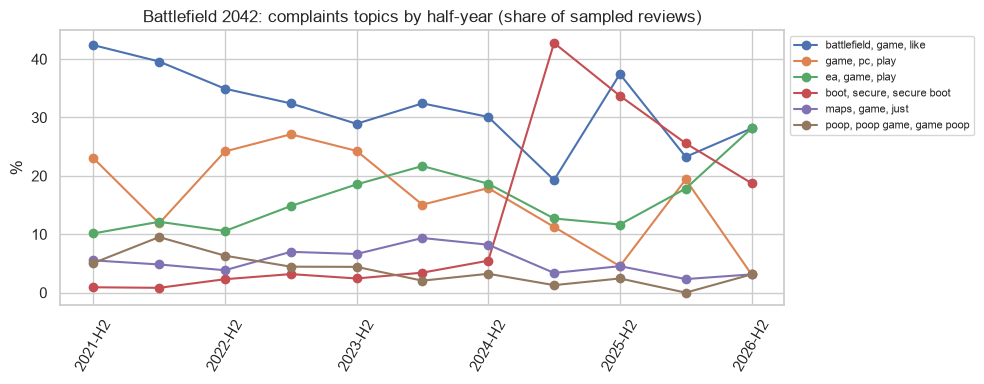

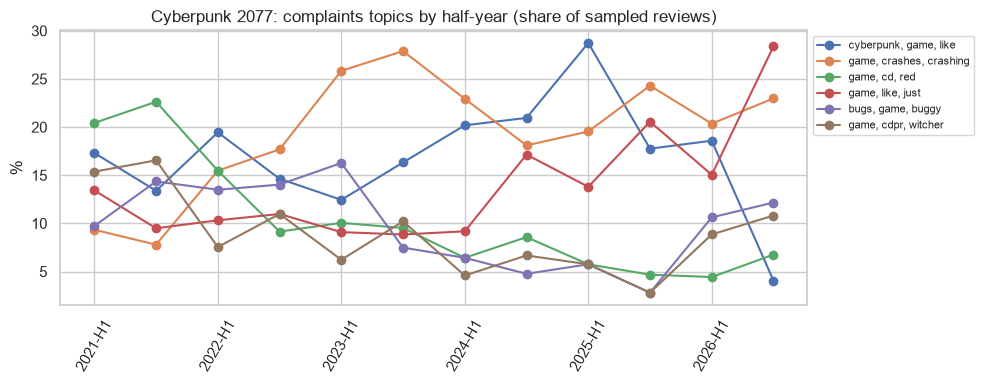

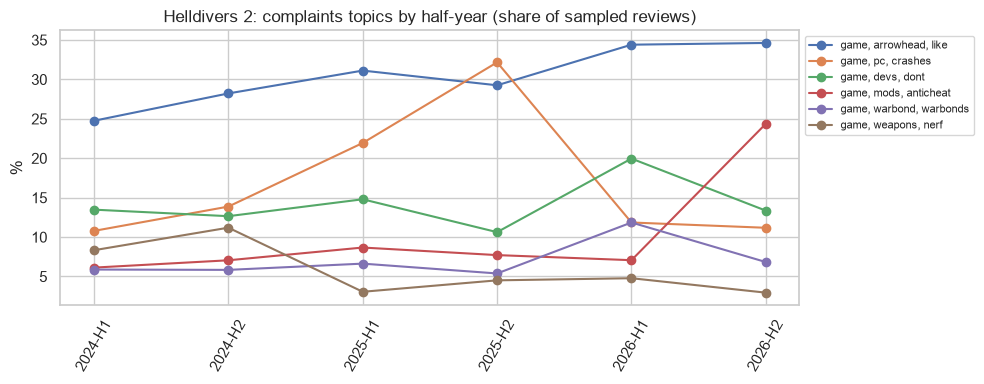

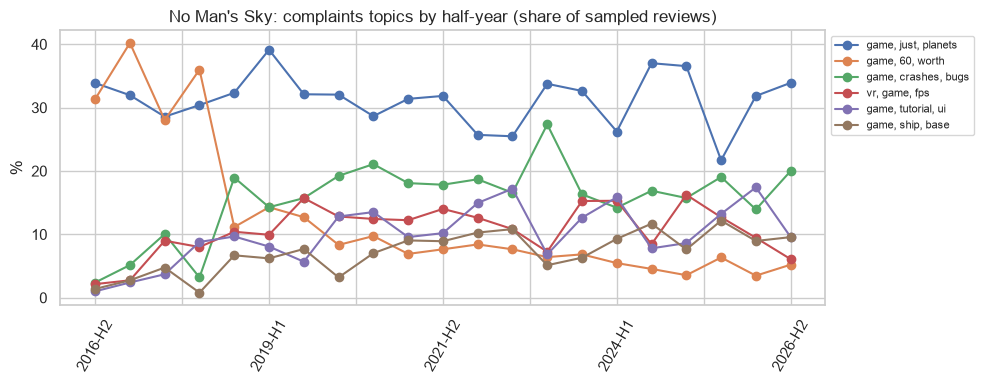

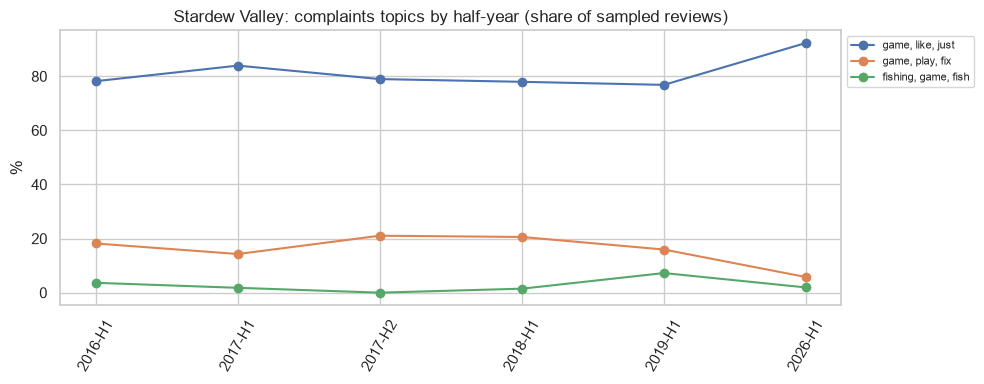

In [16]:
def plot_topic_shares(game, group, top_n=6, min_per_half=50):
    r = results.get((game, group))
    if r is None:
        print("no results for", game, group); return
    f = r["frame"]
    f = f[f["topic"] != -1]
    top = f["topic"].value_counts().head(top_n).index
    counts = f.groupby(["half", "topic"]).size().unstack(fill_value=0)
    counts = counts[counts.sum(axis=1) >= min_per_half]
    if counts.empty:
        print("not enough reviews per half-year for", game, group); return
    share = counts.div(counts.sum(axis=1), axis=0)[[t for t in top if t in counts.columns]] * 100
    share.columns = [label_for(game, group, t) for t in share.columns]
    ax = share.plot(figsize=(10, 4), marker="o")
    ax.set(title=f"{game}: {group} topics by half-year (share of sampled reviews)", xlabel="", ylabel="%")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
    plt.xticks(rotation=60)
    plt.tight_layout()
    plt.savefig(IMG / f"topics_over_time_{game.replace(' ', '_').replace(chr(39), '')}_{group}.png", dpi=150)
    plt.show()

for game in sorted(df["game"].unique()):
    plot_topic_shares(game, "complaints")

### Look at real examples from a topic

In [17]:
def show_examples(game, group, topic, n=6):
    f = results[(game, group)]["frame"]
    ex = f[f["topic"] == topic]
    return ex.sample(min(n, len(ex)), random_state=1)[["half", "review"]]

# Example: show_examples("Helldivers 2", "complaints", 0)